# Avance del sprint hasta la optimización de hiperparámetros

**Autores:** Gerson Andre Garrido Mansilla y Renzo Elvis Cerron Tome (Maestría en Ciencias con
mención en IA, UNI).

**Tema de la tesis.** Segmentación de áreas inundadas en imágenes Sentinel-2 del Perú, con dos
modelos fundacionales geoespaciales (TerraMind v1-B y Prithvi-EO-2.0 300M) y una U-Net de referencia.

**Contenido.** Este cuaderno resume lo avanzado en el sprint (datos, características, modelos e
importancia de variables) y presenta con detalle la optimización de hiperparámetros.

**Protocolo.** No se entrena nada nuevo: el cuaderno lee los registros de las corridas ya hechas.
Los hiperparámetros se eligen con Sen1Floods11 `valid`; los resultados en el Perú se miden en
`peru-dev`. Este cuaderno no lee `test`, `peru-test` ni `peru-2017-test`.

## 1. Resumen del sprint

| Etapa | Qué se hizo | Resultado principal | Detalle |
|---|---|---|---|
| Datos | Conjunto peruano sin etiquetado manual, a partir de mapas de UNOSAT 2023 y Copernicus EMS 2017 | `peru-train` 753 recortes, `peru-dev` 174 | `docs/peru_data_card.md` |
| Análisis exploratorio | Revisión de fuga de información, desbalance, cambio de dominio y etiquetas | El suelo seco peruano es mucho más brillante que el de Sen1Floods11; el agua es parecida | `notebooks/eda.ipynb` |
| Características | Clasificador por píxel con bandas, índices y contexto | Con datos del Perú, bandas crudas 0.930; los índices y el contexto no mejoran el IoU | `notebooks/feature_engineering.ipynb` |
| Modelos | Tres arquitecturas, tres semillas, entrenadas en el Perú | IoU de agua en `peru-dev`: U-Net 0.9415, TerraMind 0.9265, Prithvi 0.9218 | `docs/EXPERIMENT_LOG.md` |
| Importancia de variables | Descomposición de varianza y permutación de bandas | El esquema de entrenamiento explica el 53 % de la varianza; la banda SWIR 1 es la más importante para la U-Net | `entregables/matriz_consistencia/importancia_variables.ipynb` |
| **Hiperparámetros** | **Barrido de la tasa de aprendizaje y revisión del tope de épocas** | **Secciones 2 a 7 de este cuaderno** | |

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, yaml, matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
OUT = REPO / "outputs"
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True})

NOMBRES = {"unet": "U-Net", "terramind_v1_base": "TerraMind v1-B", "prithvi_eo_v2_300": "Prithvi-EO-2.0 300M"}
COLORES = {"unet": "#2a78d6", "terramind_v1_base": "#e0792a", "prithvi_eo_v2_300": "#1a9a7f"}


def leer(carpeta):
    """Corridas de una carpeta. La tasa viene de config.yaml (optimizer.init_args.lr), porque el campo
    lr de run.json no se usa. Las filas de entrenamiento y validación de metrics.csv están intercaladas."""
    filas, curvas = [], {}
    for p in sorted((OUT / carpeta).glob("*/lightning_logs/seed*/metrics.csv")):
        v = pd.read_csv(p).dropna(subset=["val/IoU_Flood"]).groupby("epoch")["val/IoU_Flood"].max()
        c = yaml.safe_load((p.parent / "config.yaml").read_text())
        o = c["optimizer"]["init_args"]
        modelo, semilla = p.parts[-4], p.parent.name
        filas.append(dict(carpeta=carpeta, modelo=modelo, semilla=semilla, lr=o["lr"], wd=o.get("weight_decay"),
                          lote=c["data"]["init_args"]["batch_size"], tope=c["trainer"]["max_epochs"],
                          iou=v.max(), mejor_epoca=int(v.idxmax()), ultima_epoca=int(v.index.max())))
        curvas[(carpeta, semilla)] = v
    return pd.DataFrame(filas), curvas


BARRIDO = ["s1f11_lr3e-5", "s1f11_lr1e-4", "s1f11_lr3e-4", "s1f11_lr1e-3", "s1f11_lr1e-5", "s1f11_lr2e-5", "s1f11_lr5e-5",
           "s1f11_prithvi_lr3e-5", "s1f11_prithvi_lr1e-4", "s1f11_prithvi_lr3e-4"]
FINALES = ["s1f11_src_unet", "s1f11_src_terramind_lr5e-5", "s1f11_src_prithvi"]
leidos = {c: leer(c) for c in BARRIDO + FINALES + ["s1f11_src_terramind", "s1f11_src_unet_repeat", "runs_cloud", "runs_cloud_tm200"]}
barrido = pd.concat([leidos[c][0] for c in BARRIDO], ignore_index=True).sort_values(["modelo", "lr"])
finales = pd.concat([leidos[c][0] for c in FINALES], ignore_index=True)
descartada = leidos["s1f11_src_terramind"][0]
repeticion = leidos["s1f11_src_unet_repeat"][0]
peru = leidos["runs_cloud"][0]
peru200 = leidos["runs_cloud_tm200"][0]

# Control: las cifras recalculadas coinciden con docs/EXPERIMENT_LOG.md.
esperado = {("unet", 3e-5): .7964, ("unet", 1e-4): .8140, ("unet", 3e-4): .8325, ("unet", 1e-3): .8154,
            ("terramind_v1_base", 1e-5): .7504, ("terramind_v1_base", 2e-5): .8197, ("terramind_v1_base", 5e-5): .8354,
            ("prithvi_eo_v2_300", 3e-5): .8247, ("prithvi_eo_v2_300", 1e-4): .8257, ("prithvi_eo_v2_300", 3e-4): .8170}
for (m, lr), iou in esperado.items():
    fila = barrido[(barrido.modelo == m) & np.isclose(barrido.lr, lr)]
    assert len(fila) == 1 and abs(fila.iou.iloc[0] - iou) < 1e-4, (m, lr)
print(f"{len(barrido)} corridas de barrido, {len(finales)} corridas finales; las cifras coinciden con la bitácora.")

10 corridas de barrido, 9 corridas finales; las cifras coinciden con la bitácora.


## 2. Hiperparámetros: qué se buscó y qué quedó fijo

No se buscaron todos los hiperparámetros: la búsqueda se centró en la tasa de aprendizaje y el resto
se tomó de las configuraciones de cada modelo. Los modelos comparten la pérdida (Dice), el optimizador
AdamW, el planificador `ReduceLROnPlateau` (factor 0.5, paciencia 5) y la parada temprana sobre el IoU
de agua en validación (paciencia 20).

La tabla muestra los valores leídos del `config.yaml` de cada corrida final.

In [2]:
t = finales.groupby("modelo")[["lr", "wd", "lote", "tope"]].first().loc[list(NOMBRES)]
t_peru = peru.groupby("modelo")[["lr", "tope"]].first().loc[list(NOMBRES)]
tabla = pd.DataFrame({
    "Tasa elegida (Sen1Floods11)": t.lr.map("{:.0e}".format),
    "Tasa usada (Perú)": t_peru.lr.map("{:.0e}".format),
    "Decaimiento de pesos": t.wd,
    "Tamaño de lote": t.lote,
    "Tope de épocas (Sen1Floods11)": t.tope,
    "Tope de épocas (Perú)": t_peru.tope,
}).rename(index=NOMBRES).T
display(tabla)

modelo,U-Net,TerraMind v1-B,Prithvi-EO-2.0 300M
Tasa elegida (Sen1Floods11),3e-04,5e-05,1e-04
Tasa usada (Perú),1e-04,2e-05,1e-04
Decaimiento de pesos,0.05,0.01,0.1
Tamaño de lote,8,8,4
Tope de épocas (Sen1Floods11),200,200,200
Tope de épocas (Perú),100,100,100


| Hiperparámetro | Valores | Cómo se decidió | Tipo |
|---|---|---|---|
| Tasa de aprendizaje, modelos de Sen1Floods11 | U-Net {3e-5, 1e-4, 3e-4, 1e-3}; TerraMind {1e-5, 2e-5, 5e-5}; Prithvi {3e-5, 1e-4, 3e-4} | Mejor IoU de agua en `valid`, semilla 0 | **Búsqueda en malla** |
| Tope de épocas | 100 → 200 | Dos corridas del barrido tuvieron su mejor resultado cerca del tope | **Ajuste por revisión** |
| Tasa de aprendizaje, modelos del Perú | U-Net 1e-4, TerraMind 2e-5, Prithvi 1e-4 | Valor del archivo de configuración | Fijo, sin barrido |
| Tamaño de lote | 8, 8 y 4 | Límite de memoria (`docs/feasibility.md`) | Fijo |
| Decaimiento de pesos | 0.05, 0.01 y 0.1 | Valor del archivo de configuración | Fijo |
| Pérdida, decodificador, planificador | Dice, U-Net, `ReduceLROnPlateau` | Iguales entre modelos, para compararlos | Fijo |
| Autoentrenamiento | α 0.99, q de 20 a 50 %, 4000 iteraciones | Fijados de antemano; la malla es solo sensibilidad (sección 6) | Fijo |
| β de FDA | 0.01 | Fijado de antemano | Fijo |
| *Gradient boosting* | 200 iteraciones, tasa 0.1 | Fijo; modelo exploratorio | Fijo |

**Por qué se seleccionó en `valid`.** Los modelos de Sen1Floods11 representan el caso sin datos
etiquetados del Perú. Si se eligieran sus hiperparámetros con `peru-dev`, se filtraría información de
las etiquetas peruanas hacia un método que debe funcionar sin ellas.

## 3. Barrido de la tasa de aprendizaje

Cada corrida usa la semilla 0, un tope de 100 épocas y las particiones oficiales de Sen1Floods11
(252 recortes de entrenamiento y 89 de validación). La métrica es el mejor IoU de agua en `valid`.

In [3]:
tb = barrido.assign(Modelo=barrido.modelo.map(NOMBRES), Tasa=barrido.lr.map("{:.0e}".format))
tb["Elegida"] = tb.groupby("modelo").iou.transform("max").eq(tb.iou).map({True: "sí", False: ""})
tb["Modelo"] = pd.Categorical(tb.Modelo, list(NOMBRES.values()), ordered=True)
display(tb.sort_values(["Modelo", "lr"])[["Modelo", "Tasa", "iou", "mejor_epoca", "ultima_epoca", "Elegida"]]
        .rename(columns={"iou": "IoU de agua (valid)", "mejor_epoca": "Mejor época", "ultima_epoca": "Última época"})
        .style.hide(axis="index").format({"IoU de agua (valid)": "{:.4f}"}))

Modelo,Tasa,IoU de agua (valid),Mejor época,Última época,Elegida
U-Net,3e-05,0.7964,63,83,
U-Net,1e-04,0.8140,39,59,
U-Net,3e-04,0.8325,95,99,sí
U-Net,1e-03,0.8154,39,59,
TerraMind v1-B,1e-05,0.7504,38,58,
TerraMind v1-B,2e-05,0.8197,99,99,
TerraMind v1-B,5e-05,0.8354,60,80,sí
Prithvi-EO-2.0 300M,3e-05,0.8247,74,94,
Prithvi-EO-2.0 300M,1e-04,0.8257,74,94,sí
Prithvi-EO-2.0 300M,3e-04,0.8170,64,84,


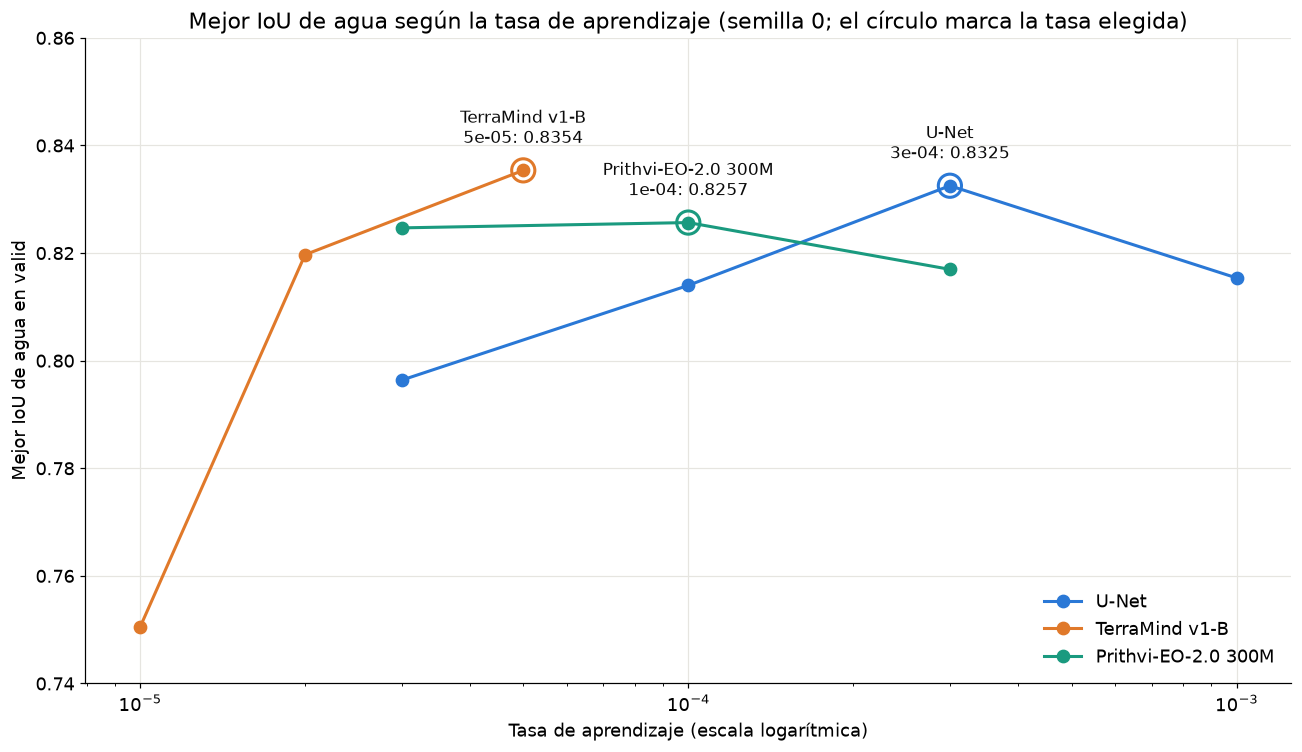

In [4]:
fig, ax = plt.subplots(figsize=(12, 7))
for m, nombre in NOMBRES.items():
    d = barrido[barrido.modelo == m].sort_values("lr")
    ax.plot(d.lr, d.iou, "-o", color=COLORES[m], lw=2, ms=8, label=nombre)
    g = d.loc[d.iou.idxmax()]
    ax.scatter(g.lr, g.iou, s=230, facecolor="none", edgecolor=COLORES[m], lw=2, zorder=3)
    ax.annotate(f"{nombre}\n{g.lr:.0e}: {g.iou:.4f}", (g.lr, g.iou), xytext=(0, 18), textcoords="offset points",
                ha="center", fontsize=11, color="#0b0b0b")
ax.set_xscale("log")
ax.set_xlabel("Tasa de aprendizaje (escala logarítmica)")
ax.set_ylabel("Mejor IoU de agua en valid")
ax.set_ylim(0.74, 0.86)
ax.set_title("Mejor IoU de agua según la tasa de aprendizaje (semilla 0; el círculo marca la tasa elegida)")
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
plt.show()

**Lectura.**
- La U-Net tiene un máximo interior en 3e-4.
- TerraMind mejora mientras sube la tasa, y su mejor valor (5e-5) queda en el borde de la malla.
- Prithvi casi no cambia: sus tres valores quedan a menos de 0.009 entre sí.

Las curvas de validación muestran además cómo se comporta cada tasa durante el entrenamiento.

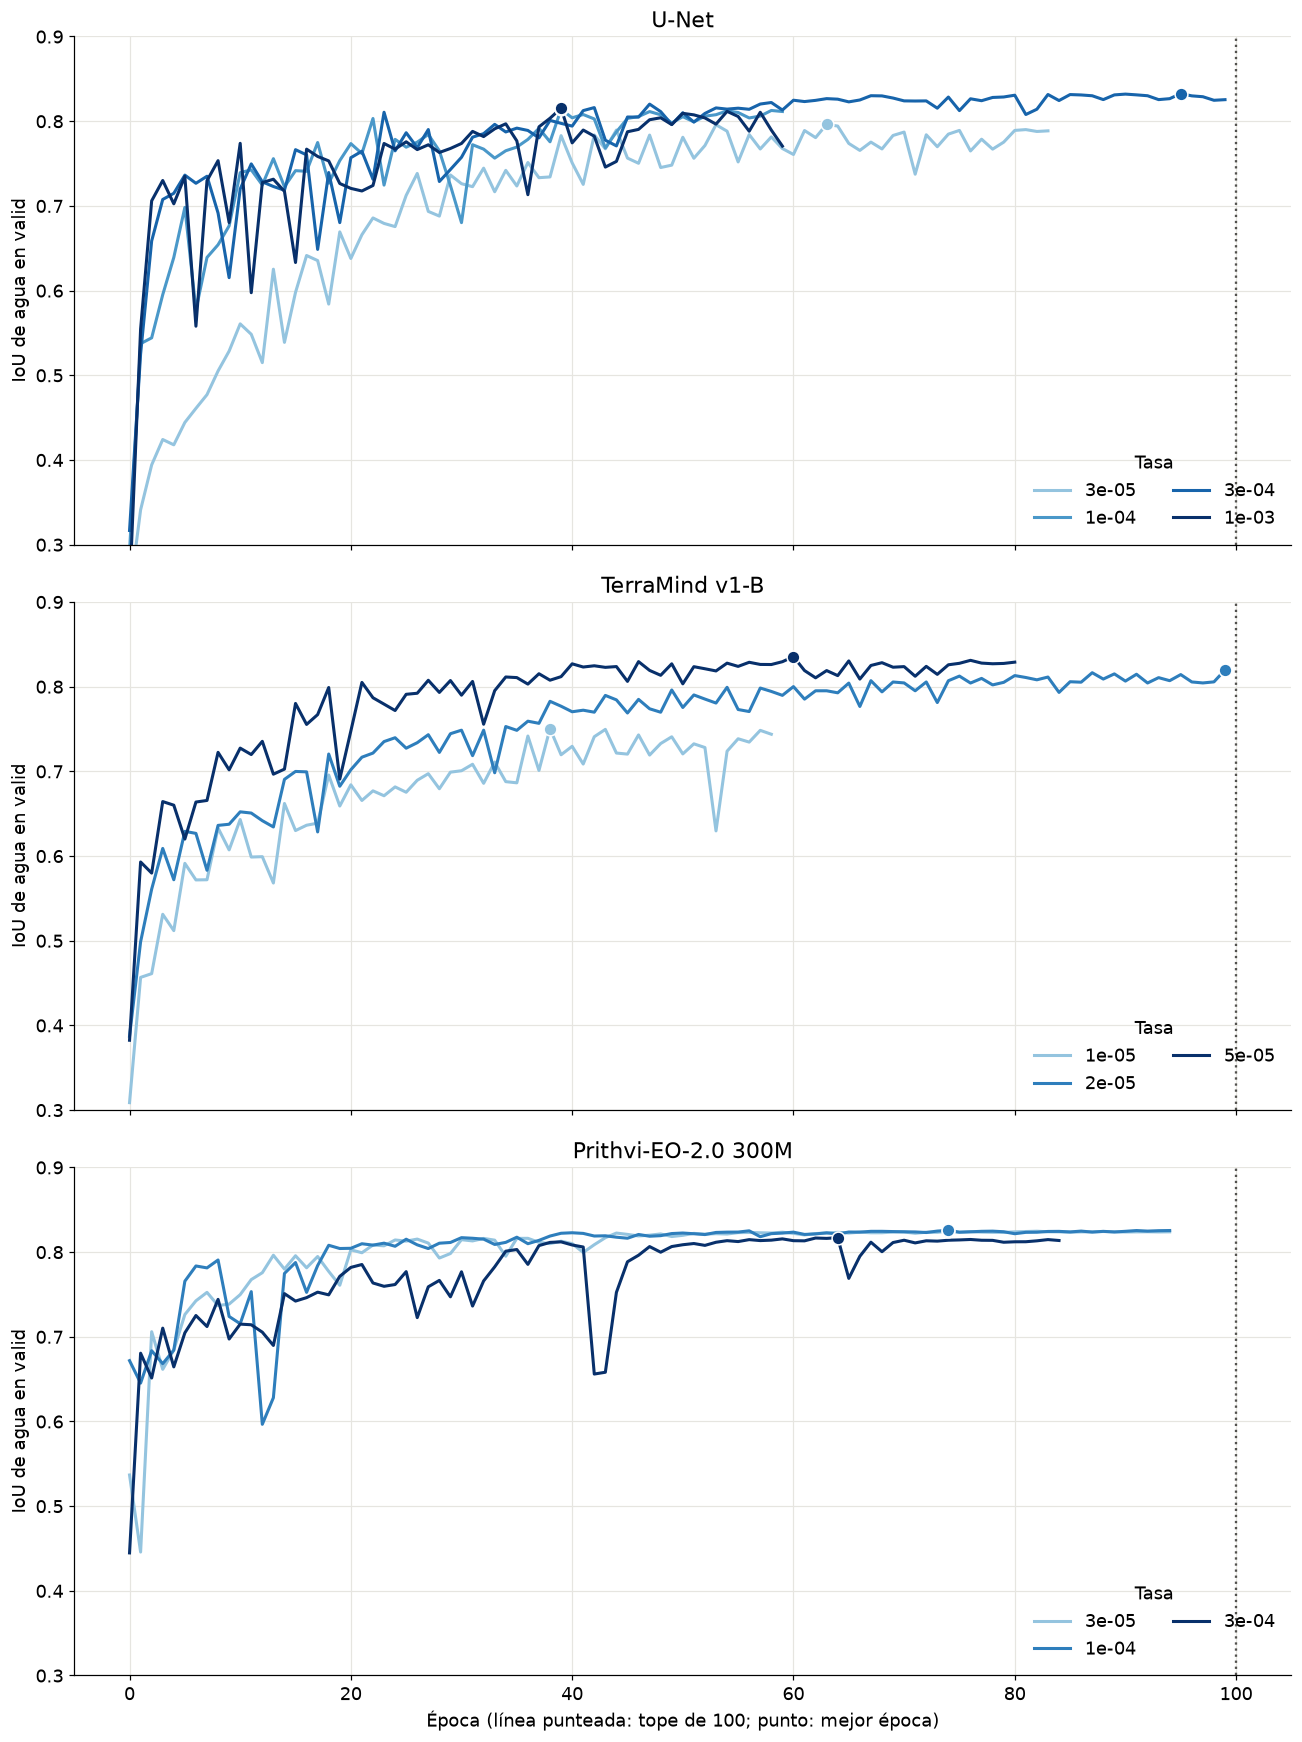

In [5]:
fig, axs = plt.subplots(3, 1, figsize=(12, 16), sharex=True)
for ax, (m, nombre) in zip(axs, NOMBRES.items()):
    d = barrido[barrido.modelo == m].sort_values("lr")
    tonos = plt.cm.Blues(np.linspace(0.4, 1.0, len(d)))
    for tono, (_, r) in zip(tonos, d.iterrows()):
        v = leidos[r.carpeta][1][(r.carpeta, r.semilla)]
        ax.plot(v.index, v.values, color=tono, lw=2, label=f"{r.lr:.0e}")
        ax.scatter(r.mejor_epoca, r.iou, color=tono, s=70, edgecolor="white", zorder=3)
    ax.axvline(100, color="#52514e", ls=":", lw=1.5)
    ax.set_ylim(0.3, 0.9)
    ax.set_ylabel("IoU de agua en valid")
    ax.set_title(nombre)
    ax.legend(title="Tasa", frameon=False, loc="lower right", ncol=2)
axs[-1].set_xlabel("Época (línea punteada: tope de 100; punto: mejor época)")
fig.tight_layout()
plt.show()

## 4. Tope de épocas

Dos corridas del barrido tuvieron su mejor resultado cerca del tope de 100 épocas: la U-Net con 3e-4
(época 95) y TerraMind con 2e-5 (época 99). Por eso, las corridas finales usaron un tope de 200.
La tabla verifica si ese tope limitó el entrenamiento.

In [6]:
f = pd.concat([finales, descartada])
te = f.groupby(["modelo", "lr"]).agg(mejor_min=("mejor_epoca", "min"), mejor_max=("mejor_epoca", "max"),
                                    ultima_max=("ultima_epoca", "max"), tope=("tope", "first")).reset_index()
te.insert(0, "Modelo", te.modelo.map(NOMBRES))
te["Tasa"] = te.lr.map("{:.0e}".format)
te["Llegó al tope"] = (te.ultima_max + 1 >= te.tope).map({True: "sí", False: "no"})
display(te[["Modelo", "Tasa", "mejor_min", "mejor_max", "ultima_max", "tope", "Llegó al tope"]]
        .rename(columns={"mejor_min": "Mejor época (mín.)", "mejor_max": "Mejor época (máx.)", "ultima_max": "Última época (máx.)", "tope": "Tope"})
        .style.hide(axis="index"))

a = peru[(peru.modelo == "terramind_v1_base") & (peru.semilla == "seed0")].iloc[0]
b = peru200.iloc[0]
display(pd.DataFrame({"Tope": [a.tope, b.tope], "IoU de agua (peru-dev)": [a.iou, b.iou], "Mejor época": [a.mejor_epoca, b.mejor_epoca],
                      "Última época": [a.ultima_epoca, b.ultima_epoca]},
                     index=["TerraMind, Perú, semilla 0", "TerraMind, Perú, semilla 0, más épocas"]))

Modelo,Tasa,Mejor época (mín.),Mejor época (máx.),Última época (máx.),Tope,Llegó al tope
Prithvi-EO-2.0 300M,1e-04,42,111,131,200,no
TerraMind v1-B,2e-05,47,112,132,200,no
TerraMind v1-B,5e-05,52,88,108,200,no
U-Net,3e-04,74,89,109,200,no


,Tope,IoU de agua (peru-dev),Mejor época,Última época
"TerraMind, Perú, semilla 0",100,0.9275,92,99
"TerraMind, Perú, semilla 0, más épocas",200,0.9270,77,97


**Lectura.** Con el tope de 200, la parada temprana terminó todas las corridas finales; el tope ya no
limita. En el Perú, TerraMind llegó a las 100 épocas en sus tres semillas, así que se repitió la
semilla 0 con un tope de 200: el IoU quedó igual (0.9270 frente a 0.9275).

## 5. Corridas finales y reproducibilidad

Con la tasa elegida se entrenaron tres semillas por modelo. La tabla incluye dos controles:
- **TerraMind con 2e-5.** Estas corridas se lanzaron por error antes de que terminara el barrido de
  5e-5. Se conservan, pero no se usan.
- **U-Net, repetición.** Es la misma corrida de la semilla 0, con los mismos ajustes.

La comparación con la configuración inicial usa la semilla 0 entrenada en Mac (bitácora, 2026-10-11/12).

In [7]:
def inicial(m):
    v = pd.read_csv(OUT / "runs" / m / "lightning_logs" / "version_1" / "metrics.csv").dropna(subset=["val/IoU_Flood"])
    return v["val/IoU_Flood"].max()

filas = []
for m, nombre in NOMBRES.items():
    d = finales[finales.modelo == m]
    filas.append({"Modelo": nombre, "Inicial (semilla 0)": inicial(m), "Tasa elegida": f"{d.lr.iloc[0]:.0e}",
                  "Media (3 semillas)": d.iou.mean(), "Desv. est.": d.iou.std()})
display(pd.DataFrame(filas).style.hide(axis="index").format(precision=4))
print(f"TerraMind con 2e-5 (descartada): {descartada.iou.mean():.4f} ± {descartada.iou.std():.4f}")
u0 = finales[(finales.modelo == "unet") & (finales.semilla == "seed0")].iloc[0]
r0 = repeticion.iloc[0]
print(f"U-Net, semilla 0: {u0.iou:.4f} (mejor época {u0.mejor_epoca}); repetición: {r0.iou:.4f} (mejor época {r0.mejor_epoca}); "
      f"diferencia {u0.iou - r0.iou:.4f}; desv. est. entre semillas {finales[finales.modelo == 'unet'].iou.std():.4f}")

Modelo,Inicial (semilla 0),Tasa elegida,Media (3 semillas),Desv. est.
U-Net,0.8188,3e-04,0.8315,0.0015
TerraMind v1-B,0.8168,5e-05,0.8349,0.0014
Prithvi-EO-2.0 300M,0.8327,1e-04,0.8315,0.0047


TerraMind con 2e-5 (descartada): 0.8141 ± 0.0151
U-Net, semilla 0: 0.8330 (mejor época 83); repetición: 0.8161 (mejor época 34); diferencia 0.0170; desv. est. entre semillas 0.0015


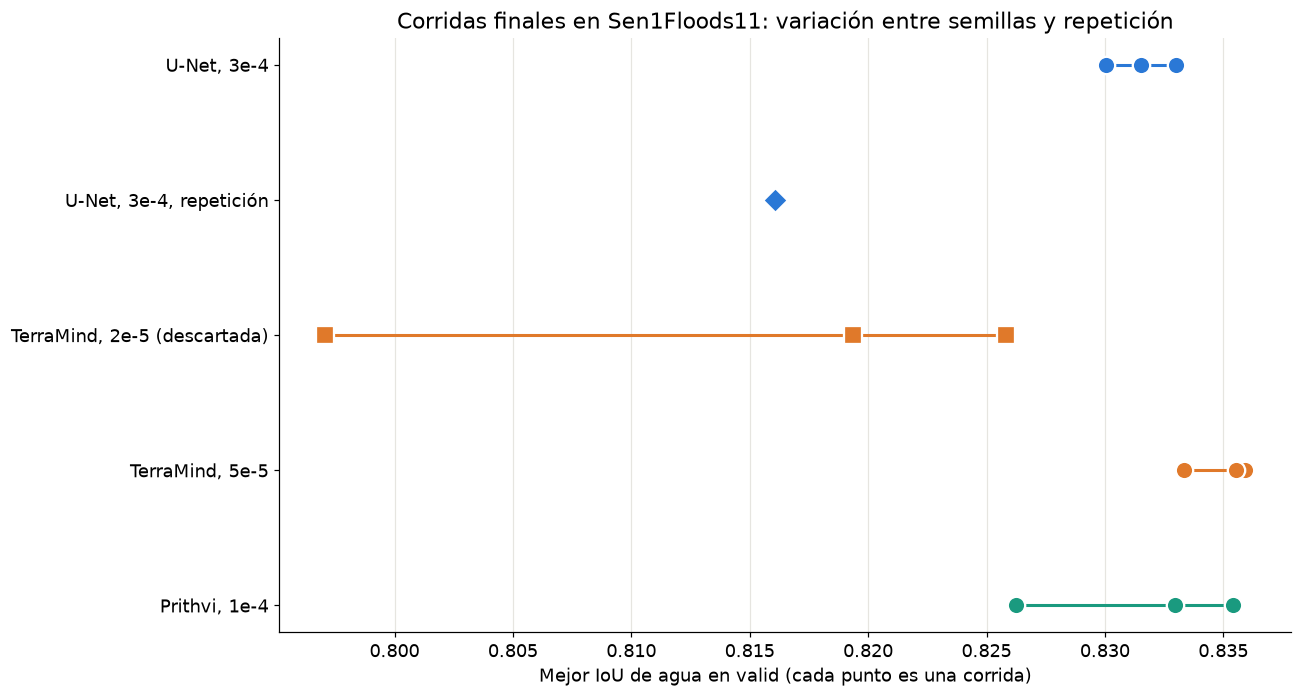

In [8]:
grupos = [("U-Net, 3e-4", finales[finales.modelo == "unet"], "unet", "o"),
          ("U-Net, 3e-4, repetición", repeticion, "unet", "D"),
          ("TerraMind, 2e-5 (descartada)", descartada, "terramind_v1_base", "s"),
          ("TerraMind, 5e-5", finales[finales.modelo == "terramind_v1_base"], "terramind_v1_base", "o"),
          ("Prithvi, 1e-4", finales[finales.modelo == "prithvi_eo_v2_300"], "prithvi_eo_v2_300", "o")]
fig, ax = plt.subplots(figsize=(12, 6.5))
for y, (nombre, d, m, marca) in enumerate(grupos):
    ax.scatter(d.iou, [y] * len(d), s=130, color=COLORES[m], marker=marca, edgecolor="white", linewidth=1.5, zorder=3)
    ax.plot([d.iou.min(), d.iou.max()], [y, y], color=COLORES[m], lw=2, zorder=2)
ax.set_yticks(range(len(grupos)), [g[0] for g in grupos])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Mejor IoU de agua en valid (cada punto es una corrida)")
ax.set_title("Corridas finales en Sen1Floods11: variación entre semillas y repetición")
fig.tight_layout()
plt.show()

**Lectura.** La repetición de la U-Net difiere en 1.7 puntos de IoU, mucho más que la desviación entre
semillas (0.15 puntos). El entrenamiento en GPU no se puede reproducir bit a bit y la parada temprana
amplifica las diferencias pequeñas. Por eso, las diferencias menores de unos 2 puntos con tres semillas
deben interpretarse con cuidado.

### 5.1. ¿La mejora se traslada al Perú?

Los mismos modelos se evaluaron en `peru-dev`. Esta partición no se usó para elegir la tasa.

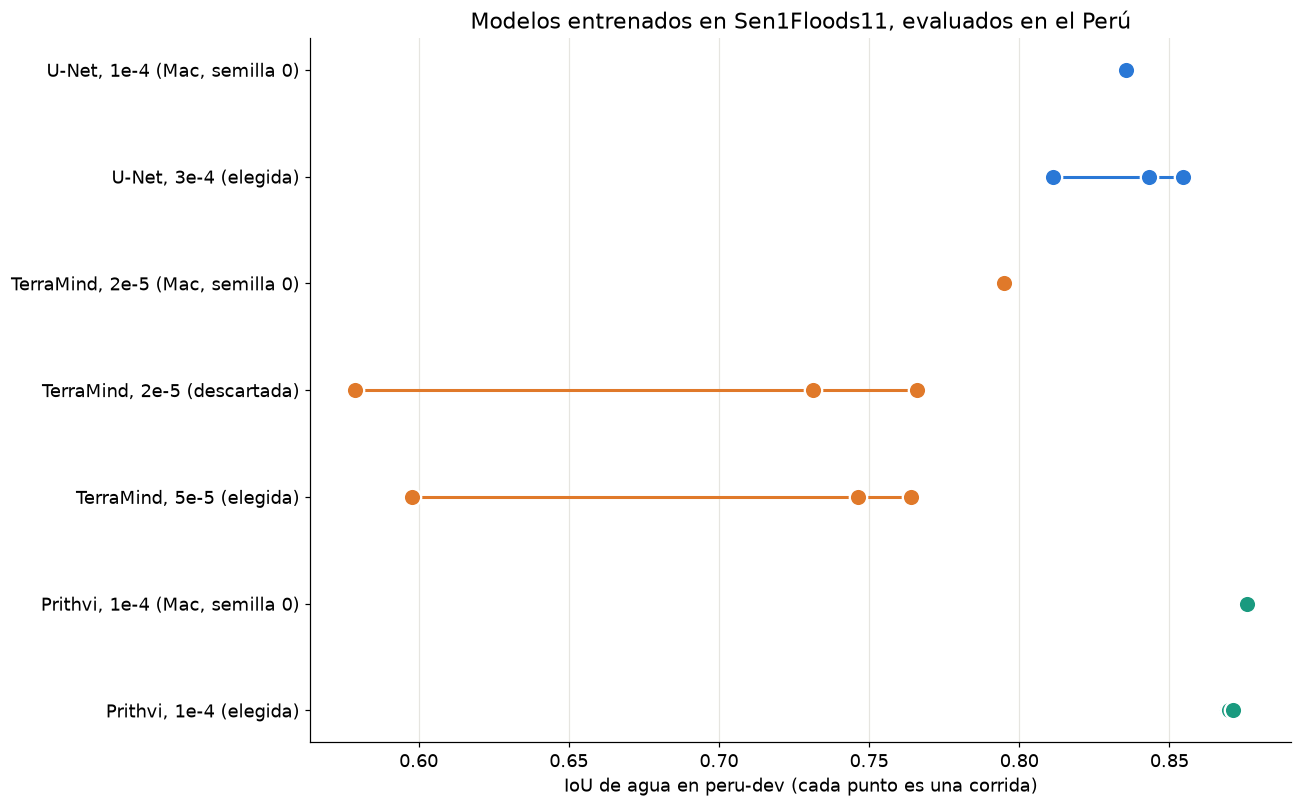

Configuración,Semillas,IoU de agua (peru-dev),Desv. est.
"U-Net, 1e-4 (Mac, semilla 0)",1,0.8354,—
"U-Net, 3e-4 (elegida)",3,0.8364,0.0224
"TerraMind, 2e-5 (Mac, semilla 0)",1,0.7951,—
"TerraMind, 2e-5 (descartada)",3,0.6921,0.0996
"TerraMind, 5e-5 (elegida)",3,0.7027,0.0913
"Prithvi, 1e-4 (Mac, semilla 0)",1,0.8758,—
"Prithvi, 1e-4 (elegida)",3,0.8701,0.0011


In [9]:
dev = pd.read_csv(OUT / "phaseD" / "dev_table_runs.csv")
filas = [("U-Net, 1e-4 (Mac, semilla 0)", "s1f11", "unet"), ("U-Net, 3e-4 (elegida)", "s1f11_src", "unet"),
         ("TerraMind, 2e-5 (Mac, semilla 0)", "s1f11", "terramind_v1_base"), ("TerraMind, 2e-5 (descartada)", "s1f11_src_lr2e-5", "terramind_v1_base"),
         ("TerraMind, 5e-5 (elegida)", "s1f11_src", "terramind_v1_base"),
         ("Prithvi, 1e-4 (Mac, semilla 0)", "s1f11", "prithvi_eo_v2_300"), ("Prithvi, 1e-4 (elegida)", "s1f11_src", "prithvi_eo_v2_300")]
filas_t = []
fig, ax = plt.subplots(figsize=(12, 7.5))
for y, (nombre, esquema, m) in enumerate(filas):
    d = dev[(dev.regime == esquema) & (dev.model == m)]
    ax.scatter(d.iou, [y] * len(d), s=130, color=COLORES[m], edgecolor="white", linewidth=1.5, zorder=3)
    if len(d) > 1:
        ax.plot([d.iou.min(), d.iou.max()], [y, y], color=COLORES[m], lw=2, zorder=2)
    filas_t.append({"Configuración": nombre, "Semillas": len(d), "IoU de agua (peru-dev)": d.iou.mean(), "Desv. est.": d.iou.std() if len(d) > 1 else np.nan})
ax.set_yticks(range(len(filas)), [f[0] for f in filas])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("IoU de agua en peru-dev (cada punto es una corrida)")
ax.set_title("Modelos entrenados en Sen1Floods11, evaluados en el Perú")
fig.tight_layout()
plt.show()
display(pd.DataFrame(filas_t).style.hide(axis="index").format({"IoU de agua (peru-dev)": "{:.4f}", "Desv. est.": "{:.4f}"}, na_rep="—"))

**Lectura.** En TerraMind, la variación entre semillas (de 0.58 a 0.77 con 2e-5) es mayor que la
diferencia entre tasas. Incluso con la misma tasa, la corrida en Mac (0.795) y las corridas en GPU
quedan lejos entre sí. Prithvi es el más estable y también el mejor de los tres en el Perú sin
adaptación.

## 6. Sensibilidad de otros hiperparámetros

Estas búsquedas **no se usaron para elegir la configuración**. Usan las etiquetas de `peru-dev` y solo
muestran cuánto cambia el resultado.

### 6.1. Autoentrenamiento: α y q

Parámetros de la malla: α es el coeficiente de la media móvil del modelo profesor y q es la proporción
final de píxeles con pseudoetiqueta. Se usó la semilla 0, en cuatro puntos de control, con el modelo profesor evaluado con AdaBN.

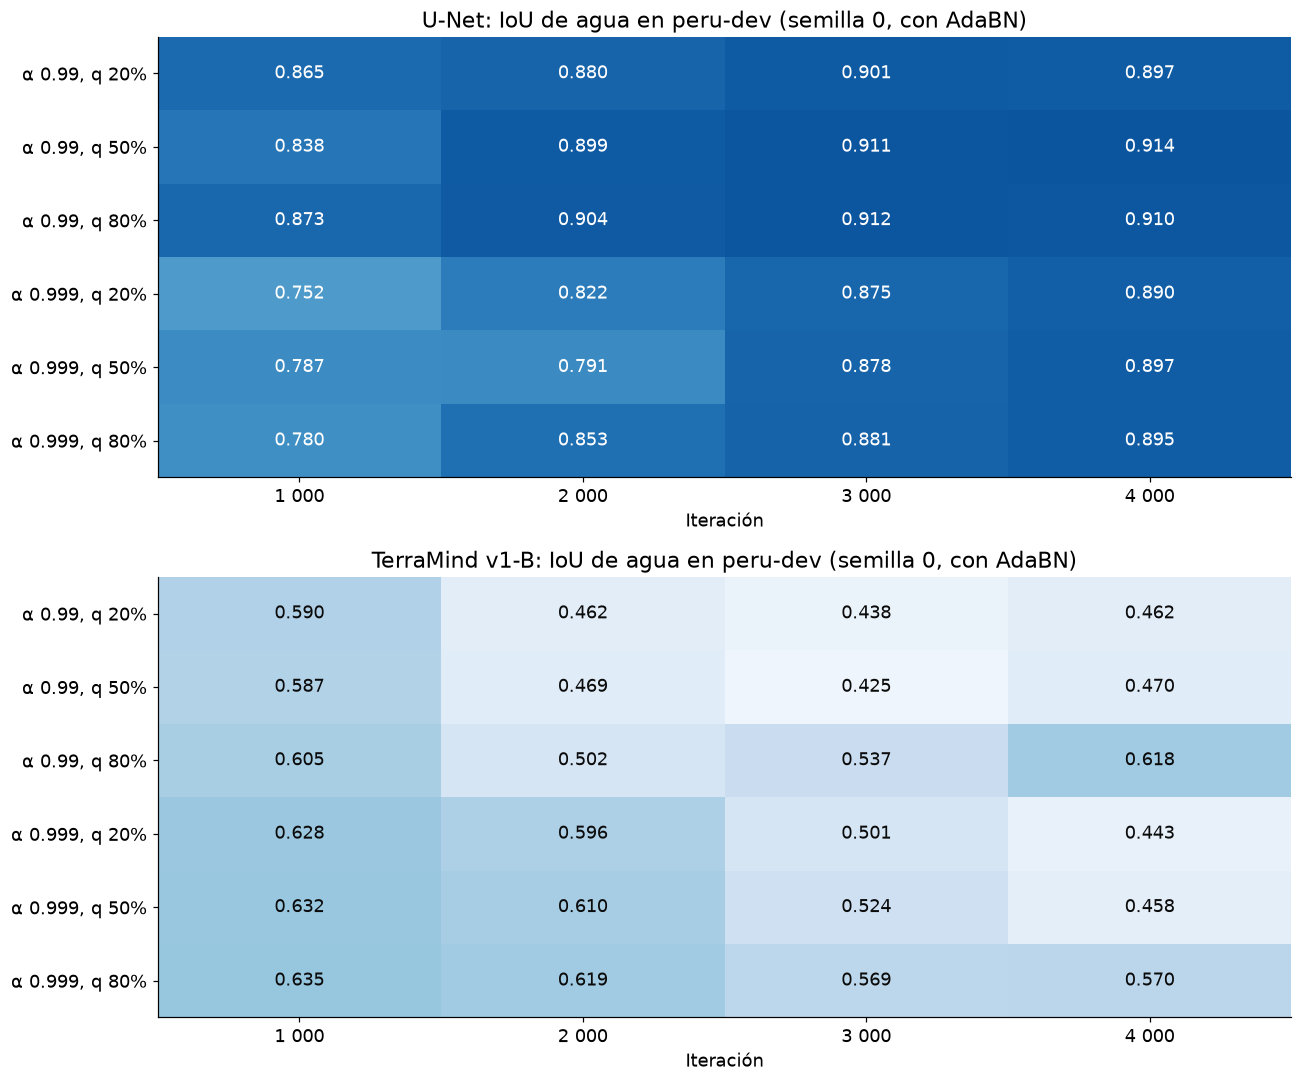

Sin adaptar, semilla 0: U-Net 0.8433 · TerraMind 0.7639


In [10]:
or_ = pd.read_csv(OUT / "phaseD" / "oracle_selection.csv")
or_ = or_[or_.tag.str.startswith("st")]
fig, axs = plt.subplots(2, 1, figsize=(12, 10))
for ax, m in zip(axs, ["unet", "terramind_v1_base"]):
    p = or_[or_.model == m].pivot_table(index=["alpha", "q_end"], columns="iter", values="iou")
    im = ax.imshow(p.values, cmap="Blues", vmin=0.4, vmax=1.0, aspect="auto")
    ax.set_xticks(range(p.shape[1]), [f"{c:,}".replace(",", " ") for c in p.columns])
    ax.set_yticks(range(p.shape[0]), [f"α {a}, q {q:.0%}" for a, q in p.index])
    ax.grid(False)
    for i in range(p.shape[0]):
        for j in range(p.shape[1]):
            v = p.values[i, j]
            ax.text(j, i, f"{v:.3f}", ha="center", va="center", color="white" if v > 0.75 else "#0b0b0b")
    ax.set_title(f"{NOMBRES[m]}: IoU de agua en peru-dev (semilla 0, con AdaBN)")
    ax.set_xlabel("Iteración")
fig.tight_layout()
plt.show()
print("Sin adaptar, semilla 0: U-Net", round(dev[(dev.regime == "s1f11_src") & (dev.model == "unet") & (dev.seed == "seed0")].iou.iloc[0], 4),
      "· TerraMind", round(dev[(dev.regime == "s1f11_src") & (dev.model == "terramind_v1_base") & (dev.seed == "seed0")].iou.iloc[0], 4))

### 6.2. Umbral de MNDWI

La línea base más simple tiene un solo hiperparámetro: el umbral del índice. Se muestra el IoU de agua
según el umbral en cada dominio.

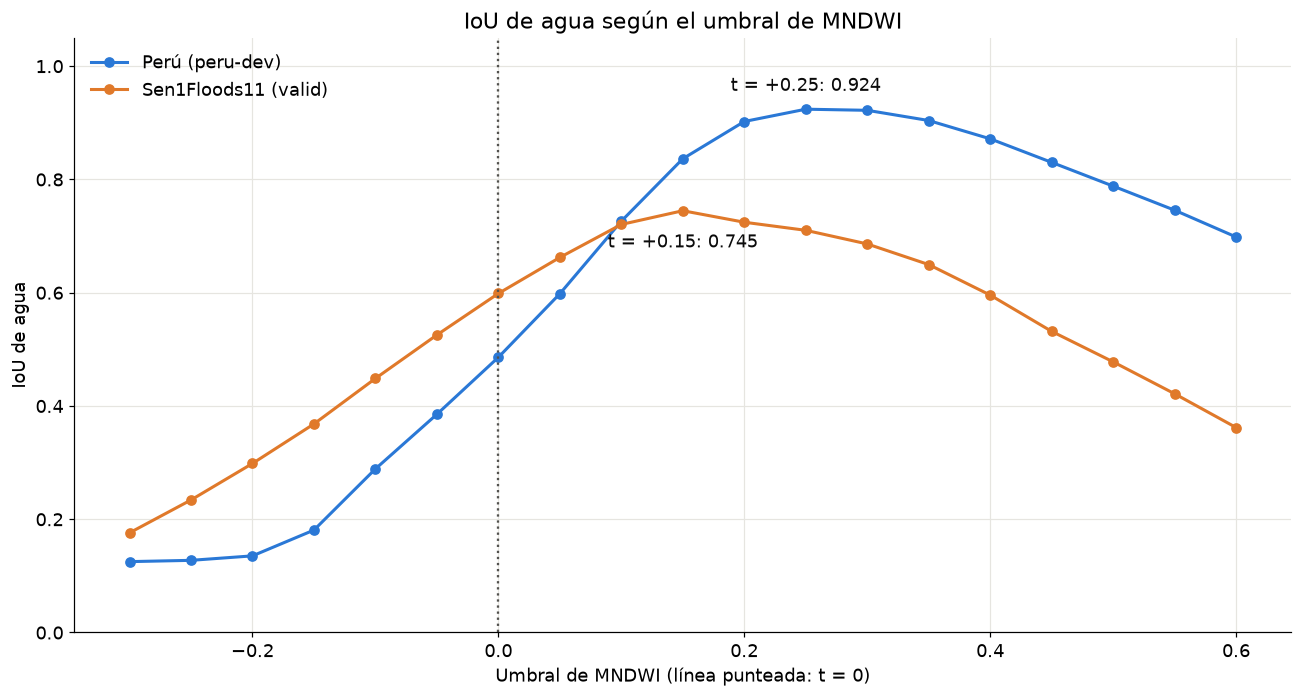

In [11]:
ind = pd.read_csv(OUT / "analysis_dev" / "index_baseline.csv")
ind = ind[(ind["index"] == "MNDWI") & np.isclose(ind.t * 20, (ind.t * 20).round())]  # sin los umbrales de Otsu
fig, ax = plt.subplots(figsize=(12, 6.5))
for split, color, nombre, dy in [("peru-dev", "#2a78d6", "Perú (peru-dev)", 12), ("Sen1Floods11 valid", "#e0792a", "Sen1Floods11 (valid)", -24)]:
    d = ind[ind.split == split].sort_values("t")
    ax.plot(d.t, d.iou, "-o", color=color, lw=2, ms=6, label=nombre)
    g = d.loc[d.iou.idxmax()]
    ax.annotate(f"t = {g.t:+.2f}: {g.iou:.3f}", (g.t, g.iou), xytext=(0, dy), textcoords="offset points", ha="center", color="#0b0b0b")
ax.axvline(0, color="#52514e", ls=":", lw=1.5)
ax.set_xlabel("Umbral de MNDWI (línea punteada: t = 0)")
ax.set_ylabel("IoU de agua")
ax.set_ylim(0, 1.05)
ax.set_title("IoU de agua según el umbral de MNDWI")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

**Lectura.** El mejor umbral cambia entre dominios (+0.25 en el Perú y +0.15 en Sen1Floods11). Sin
datos etiquetados del Perú, el umbral no se puede ajustar: con Otsu sobre las imágenes de `peru-train` sin
etiquetar, el IoU de agua es 0.5718.

## 7. Configuración resultante

In [12]:
filas = []
for m, nombre in NOMBRES.items():
    a, b = finales[finales.modelo == m], peru[peru.modelo == m]
    s = dev[(dev.regime == "s1f11_src") & (dev.model == m)].iou
    filas.append({"Modelo": nombre, "Sen1Floods11: tasa": f"{a.lr.iloc[0]:.0e}", "IoU valid": f"{a.iou.mean():.4f} ± {a.iou.std():.4f}",
                  "IoU peru-dev (sin adaptar)": f"{s.mean():.4f} ± {s.std():.4f}",
                  "Perú: tasa (sin barrido)": f"{b.lr.iloc[0]:.0e}", "IoU peru-dev (entrenado en el Perú)": f"{b.iou.mean():.4f} ± {b.iou.std():.4f}"})
display(pd.DataFrame(filas).style.hide(axis="index"))

Modelo,Sen1Floods11: tasa,IoU valid,IoU peru-dev (sin adaptar),Perú: tasa (sin barrido),IoU peru-dev (entrenado en el Perú)
U-Net,3e-04,0.8315 ± 0.0015,0.8364 ± 0.0224,1e-04,0.9415 ± 0.0019
TerraMind v1-B,5e-05,0.8349 ± 0.0014,0.7027 ± 0.0913,2e-05,0.9265 ± 0.0025
Prithvi-EO-2.0 300M,1e-04,0.8315 ± 0.0047,0.8701 ± 0.0011,1e-04,0.9218 ± 0.0007


## 8. Conclusiones

**Qué se optimizó.**

- Se hizo una búsqueda en malla de la tasa de aprendizaje para los tres modelos entrenados en
  Sen1Floods11, con 10 corridas (semilla 0) y selección en `valid`. Se eligió 3e-4 para la U-Net,
  5e-5 para TerraMind y 1e-4 para Prithvi.
- También se subió el tope de 100 a 200 épocas para las corridas finales, porque dos corridas del
  barrido tuvieron su mejor resultado cerca del tope. Con 200 épocas, ninguna corrida final llegó
  al tope.

**Qué se ganó.**

- En `valid`, el IoU de agua de la U-Net subió de 0.819 a 0.832 y el de TerraMind de 0.817 a 0.835.
  Prithvi se mantuvo (0.833 frente a 0.832), porque su mejor tasa es la que ya tenía.
- En TerraMind, la mejora se confirma con tres semillas: 0.835 ± 0.001 con 5e-5 frente a
  0.814 ± 0.015 con 2e-5. Además, sus resultados varían mucho menos entre semillas.
- En la U-Net, la ventaja de 3e-4 sobre la segunda tasa (0.017) es igual a la diferencia que se
  obtuvo al repetir la misma corrida (0.017). Por eso no se puede afirmar que 3e-4 sea claramente
  la mejor tasa. En Prithvi, las tres tasas quedan a menos de 0.009 entre sí.

**La mejora no se trasladó al Perú.** Con la tasa elegida, TerraMind obtiene 0.703 ± 0.091 en
`peru-dev`, frente a 0.692 ± 0.100 con 2e-5. La diferencia es mucho menor que la variación entre
semillas. La U-Net queda en 0.836 ± 0.022, frente a 0.835 con su tasa original (una sola semilla).
Ajustar los hiperparámetros dentro del dominio de origen no resuelve el cambio de dominio. Esto
coincide con la importancia de variables de la semana 7: el esquema de entrenamiento pesa mucho más
en el IoU que los demás factores.

**Sensibilidad.**

- En el autoentrenamiento con AdaBN y semilla 0, ninguna combinación de α y q supera al modelo sin
  adaptar en TerraMind (0.764). En la U-Net, las combinaciones quedan entre 0.890 y 0.914 a las 4000
  iteraciones, por encima del modelo sin adaptar (0.843). Este resultado no es estable: con las
  semillas 1 y 2, la configuración por defecto pierde entre 0.01 y 0.11, y la media de las tres
  semillas (0.818 ± 0.110) queda por debajo del modelo sin adaptar (0.836 ± 0.022).
- El umbral de MNDWI es muy sensible: el IoU de agua en `peru-dev` pasa de 0.486 con t = 0 a 0.924
  con t = 0.25. Ese umbral se ajustó con las etiquetas de `peru-dev`, así que es una referencia
  optimista.

**Limitaciones.**

- **Los modelos entrenados en el Perú no tuvieron barrido propio.** La U-Net (0.9415), TerraMind
  (0.9265) y Prithvi (0.9218) usan las tasas de sus archivos de configuración. Por eso, sus
  resultados no representan el mejor valor posible con una búsqueda en `peru-dev`.
- Solo se buscó la tasa de aprendizaje, con búsqueda en malla y una semilla. No se usó búsqueda
  aleatoria ni bayesiana. El decaimiento de pesos, el tamaño de lote, la función de pérdida, el
  decodificador, el planificador, β de FDA y los parámetros del *gradient boosting* quedaron fijos.
- La tasa 5e-5 de TerraMind está en el borde de su malla; una tasa mayor podría ser mejor. Para
  Prithvi se fijó de antemano una regla de ampliación de la malla, que no hizo falta aplicar.
- Las cifras de `valid` son optimistas, porque la tasa, la parada temprana y el punto de control
  se eligen con esa misma partición. Solo sirven para ordenar configuraciones.
- El entrenamiento en GPU no se puede reproducir bit a bit. Una diferencia menor de unos 2 puntos
  de IoU entre configuraciones, con tres semillas, debe interpretarse con cuidado.
- La revisión del tope de épocas en el Perú se hizo solo para TerraMind con la semilla 0. La U-Net
  con semilla 1 también tuvo su mejor resultado cerca del tope (época 98) y no se revisó.

**Pendiente.** Un barrido de la tasa de aprendizaje con `peru-train` y selección en `peru-dev`
mostraría cuánto se puede ganar en los modelos entrenados en el Perú. Este cuaderno no usa ninguna
partición de prueba.
